# Phase 9 — Cost-sensitive three-way decision router

 convert Phase 8's calibrated P(abusive) and Mondrian conformal prediction sets
into one of three business actions — **auto-approve**, **inspect**, or **escalate** — in a way
that minimises the official cost-weighted loss while keeping genuine customers protected and
the three fairness groups (new customers, low-value orders, non-English text) within tolerance.

In [20]:
import json
import platform
import sys
from pathlib import Path

for candidate_path in (Path('../src'), Path('src')):
    if candidate_path.exists():
        sys.path.insert(0, str(candidate_path.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score

from r2sorter.baselines import build_model, catboost_inputs, predict_full
from r2sorter.calibration import AbuseCalibrator
from r2sorter.config import load_config
from r2sorter.conformal import cross_fit_calibrated
from r2sorter.data import LABELS, load_all
from r2sorter.ensemble import evaluate_routing, fairness_masks, fast_official, paired_bootstrap, row_costs
from r2sorter.fairness import audit
from r2sorter.nlp import classification_report, language_group3
from r2sorter.protocol import build_protocol
from r2sorter.router import route
from r2sorter.scoring import official_score

pd.set_option('display.width', 220, 'display.max_columns', 50, 'display.max_colwidth', 80)
AB      = LABELS.index('abusive')
SEEDS   = (0, 1, 2)
cfg     = load_config()
data    = load_all(cfg)
REPORTS = Path('../reports') if Path('../reports').exists() else Path('reports')
MODELS  = REPORTS.parent / 'models' / 'phase9'
FIG     = REPORTS / 'figures'
for folder in (REPORTS, MODELS, FIG):
    folder.mkdir(parents=True, exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
print(versions)
print('official cost matrix:', cfg['costs'])


{'python': '3.14.3', 'numpy': '2.4.3', 'pandas': '3.0.1', 'scikit-learn': '1.8.0'}
official cost matrix: {'genuine': {'auto_approve': 0.0, 'inspect': 0.5, 'escalate': 10.0}, 'abusive': {'auto_approve': 1.0, 'inspect': 0.3, 'escalate': 0.0}}


## 1. Load Phase 8 predictions
Phase 8 saves one row per validation request with calibrated probabilities, Mondrian
conformal prediction sets and the ambiguous-abusive flag. This notebook treats those
as fixed inputs — no retraining occurs here.


In [21]:
protocol = build_protocol(cfg, data)
parts, y_idx, y_abuse = protocol.parts, protocol.y_index, protocol.y_abuse

phase8_path = REPORTS / 'phase8_validation_predictions.csv'
assert phase8_path.exists(), 'Run Phase 8 first — phase8_validation_predictions.csv is missing'
p8 = pd.read_csv(phase8_path)
assert p8['return_id'].tolist() == parts['test']['return_id'].tolist(), \
    'Phase 8 rows differ from this protocol: check that Phases 5-8 used the same split'

# Core arrays used throughout
p_cal      = p8['p_abusive_calibrated'].to_numpy()   # chosen calibrator, fitted on calibration part
p_raw      = p8['p_abusive_raw'].to_numpy()
ambig_flag = p8['ambiguous_abusive_flag'].to_numpy().astype(bool)  # Mondrian set: abusive + ≥1 genuine class
set_size   = p8['set_size_mondrian'].to_numpy().astype(int)
y_test     = y_abuse['test']
truth_frame = parts['test']
masks_test  = fairness_masks(truth_frame, cfg)

# Verify baseline router matches Phase 8's decision preview
baseline_preview = p8['decision_preview_cost_router'].to_numpy()
baseline_decisions = np.array(route(p_cal, cfg))
assert (baseline_preview == baseline_decisions).all(), \
    'Baseline decisions differ from Phase 8 preview — check config or calibration'
print(f'rows: {len(p_cal):,} | abusive: {int(y_test.sum())} ({y_test.mean():.2%})')
print(f'ambiguous conformal flags: {ambig_flag.sum():,} ({ambig_flag.mean():.2%})')
print(f'baseline decisions: {pd.Series(baseline_decisions).value_counts().to_dict()}')


rows: 8,497 | abusive: 699 (8.23%)
ambiguous conformal flags: 2,664 (31.35%)
baseline decisions: {'auto_approve': 8057, 'inspect': 423, 'escalate': 17}


## 2. Verify the fast official score on the validation window
Before building any router, confirm that `fast_official` matches the real `official_score`
on the validation rows. Every router comparison below uses the fast version.


In [22]:
pred_df_base = pd.DataFrame({
    'return_id':     truth_frame['return_id'].values,
    'decision':      baseline_decisions,
    'confidence':    p_cal,
    'justification': 'Phase 9 router verification',
})
real  = official_score(pred_df_base, truth_frame)
fast  = fast_official(p_cal, y_test, masks_test, cfg)
score_ok   = abs(real['primary_score']   - fast['primary'])   < 1e-4
fairness_ok = abs(real.get('fairness_score', fast['fairness']) - fast['fairness']) < 1e-4
print(f'official scorer : {real["primary_score"]:.6f}')
print(f'fast version    : {fast["primary"]:.6f}')
assert score_ok and fairness_ok, 'fast_official differs from official_score — do not trust the router search'
print('FAST SCORE MATCHES THE OFFICIAL SCORER')


official scorer : 0.337609
fast version    : 0.337609
FAST SCORE MATCHES THE OFFICIAL SCORER


## 3. Cost matrix and shared evaluation helper
The official cost matrix from config: genuine approve=0, inspect=0.5, escalate=10;
abusive approve=1, inspect=0.3, escalate=0.
**Wrong block (genuine escalated) costs 10× a missed fraud (abusive approved).**


In [23]:
print('cost matrix:', cfg['costs'])

def evaluate_router(name, decisions, p_cal_arr, truth_fr, y_true):
    """Run official scorer + fairness audit; return one summary dict."""    
    decisions = np.asarray(decisions)
    pred_df = pd.DataFrame({
        'return_id':     truth_fr['return_id'].values,
        'decision':      decisions,
        'confidence':    p_cal_arr,
        'justification': f'Phase 9 router: {name}',
    })
    result  = official_score(pred_df, truth_fr)
    fair    = audit(truth_fr, pd.Series(decisions, index=truth_fr.index), cfg)
    flagged = decisions != 'auto_approve'
    approve_all = np.where(y_true == 1,
                           cfg['costs']['abusive']['auto_approve'],
                           cfg['costs']['genuine']['auto_approve'])
    costs = row_costs(p_cal_arr, y_true, cfg)
    return {
        'router':                    name,
        'official_score':            result['primary_score'],
        'fairness_score':            fair['fairness_score'],
        'saving':                    1 - costs.sum() / approve_all.sum(),
        'cost_per_request':          costs.mean(),
        'abusive_recall':            float(flagged[y_true == 1].mean()),
        'abusive_PR_AUC':            average_precision_score(y_true, p_cal_arr),
        'genuine_false_block_rate':  float(flagged[y_true == 0].mean()),
        'genuine_escalated':         int(((decisions == 'escalate') & (y_true == 0)).sum()),
        'auto_approve_n':            int((decisions == 'auto_approve').sum()),
        'inspect_n':                 int((decisions == 'inspect').sum()),
        'escalate_n':                int((decisions == 'escalate').sum()),
        'new_vs_established_ratio':  fair.get('new_vs_established', {}).get('ratio'),
        'low_vs_other_value_ratio':  fair.get('low_vs_other_value', {}).get('ratio'),
        'non_english_ratio':         fair.get('non_english_vs_english', {}).get('ratio'),
    }

results_store = {}   # router label -> decisions array
router_rows   = []   # one dict per router


cost matrix: {'genuine': {'auto_approve': 0.0, 'inspect': 0.5, 'escalate': 10.0}, 'abusive': {'auto_approve': 1.0, 'inspect': 0.3, 'escalate': 0.0}}


## 4. Router A — Baseline cost router
Plain `route()`: pick the action with the lowest expected cost given P(abusive).
Identical to every prior phase. Every other router must improve on this.


In [24]:
decisions_A = baseline_decisions.copy()
results_store['A: baseline cost'] = decisions_A
row_A = evaluate_router('A: baseline cost', decisions_A, p_cal, truth_frame, y_test)
router_rows.append(row_A)
print(f"Router A | official {row_A['official_score']:.4f} | fairness {row_A['fairness_score']:.4f} "
      f"| saving {row_A['saving']:.4f} | genuine escalated {row_A['genuine_escalated']}")


Router A | official 0.3376 | fairness 0.6611 | saving 0.2934 | genuine escalated 0


## 5. Router B — Conformal-aware router
Same minimum expected-cost rule as A, but any request whose Mondrian (90%) prediction
set contains `abusive` **together with at least one genuine class** is promoted one tier:
auto-approve → inspect, inspect → escalate.
Escalation is never demoted. Genuine-only sets (no `abusive`) are unchanged.

Rationale: when the model's uncertainty is high enough that a genuine reason cannot be
ruled out, the asymmetric cost (wrong block = 10, missed fraud = 1) means a human check
costs less in expectation than either auto-approving or blindly escalating.


In [25]:
TIER_UP = {'auto_approve': 'inspect', 'inspect': 'escalate', 'escalate': 'escalate'}

def conformal_promote(base_decisions, ambiguous_mask):
    out = np.array(base_decisions, copy=True)
    out[ambiguous_mask] = np.vectorize(TIER_UP.__getitem__)(out[ambiguous_mask])
    return out

decisions_B = conformal_promote(decisions_A, ambig_flag)
results_store['B: conformal-aware'] = decisions_B
row_B = evaluate_router('B: conformal-aware', decisions_B, p_cal, truth_frame, y_test)
router_rows.append(row_B)
promoted = (decisions_B != decisions_A).sum()
print(f"Router B | official {row_B['official_score']:.4f} | fairness {row_B['fairness_score']:.4f} "
      f"| saving {row_B['saving']:.4f} | genuine escalated {row_B['genuine_escalated']}")
print(f'Conformal promotion: {promoted:,} requests moved to a higher tier ({promoted/len(decisions_A):.2%})')


Router B | official -0.7000 | fairness 0.8416 | saving 0.2934 | genuine escalated 0
Conformal promotion: 2,664 requests moved to a higher tier (31.35%)


## 6. Router C — Fairness-adjusted router
Same minimum expected-cost rule as A, but the **inspect threshold is raised** for three
protected groups so that each group's genuine false-block rate does not exceed the
overall rate from Router A by more than `FAIRNESS_TOLERANCE`.

Groups checked:
- **New customers** (tenure < config threshold) — less history inflates apparent risk.
- **Low-value orders** (bottom tercile of training-set order values) — small orders
  may be penalised disproportionately.
- **Non-English text** (Hinglish or Hindi-dominant) — NLP uncertainty can leak into
  higher inspection rates for non-English reasons.

The threshold search runs on the **calibration part only** (10% hold-out, never the
reported window). The escalation threshold is never adjusted: escalation requires a
strong fraud signal regardless of group.


In [26]:
FAIRNESS_TOLERANCE  = 0.02   # max allowed excess genuine FBR above overall (2 pp)
N_THRESHOLD_STEPS   = 100    # resolution of the grid search

# ── Calibration-part inputs ───────────────────────────────────────────────────
x_train_p = protocol.matrix('tree', 'train')
x_cal_p   = protocol.matrix('tree', 'calibration')
cb_train, cat_names = catboost_inputs(x_train_p)
cb_cal = catboost_inputs(x_cal_p)[0]

# Rebuild calibrated P(abusive) on the calibration part with a 5-fold cross-fit
# (same method Phase 8 used for calibrator selection)
phase8_cfg_path = REPORTS / 'phase8_config.json'
if phase8_cfg_path.exists():
    ph8cfg = json.loads(phase8_cfg_path.read_text())
    chosen_method = ph8cfg.get('chosen_calibrator', 'bagged isotonic')
    LABEL_TO_METHOD = {'Platt (sigmoid)': 'sigmoid', 'isotonic': 'isotonic', 'bagged isotonic': 'bagged_isotonic'}
    chosen_method_key = LABEL_TO_METHOD.get(chosen_method, 'bagged_isotonic')
    print('Phase 8 chosen calibrator:', chosen_method)
else:
    chosen_method_key = 'bagged_isotonic'
    print('phase8_config.json not found — defaulting to bagged_isotonic')

_cat_model = build_model('catboost', 0, cat_names)
_cat_model.fit(cb_train, y_idx['train'])
_probs_cal_4class = predict_full(_cat_model, cb_cal)
_raw_cal = _probs_cal_4class[:, AB]
y_cal_bin = y_abuse['calibration']
p_cal_calpart = cross_fit_calibrated(_raw_cal, y_cal_bin, chosen_method_key, folds=5)
print(f'calibration part: {len(y_cal_bin):,} rows | abusive: {int(y_cal_bin.sum())} ({y_cal_bin.mean():.2%})')

# ── Group masks on calibration part ──────────────────────────────────────────
cal_frame = parts['calibration']
tercile_edges = parts['train']['order_value_inr'].quantile([1/3, 2/3]).to_numpy()
lang_cal = language_group3(cal_frame['customer_reason'])

protected_cal = {
    'new_customer': (cal_frame['customer_tenure_days'] < cfg['fairness']['new_customer_days']).to_numpy(),
    'low_value':    (cal_frame['order_value_inr'] < tercile_edges[0]).to_numpy(),
    'non_english':  (lang_cal != 'english_like').to_numpy(),
}

# ── Baseline FBR on calibration part ─────────────────────────────────────────
base_d_cal = np.array(route(p_cal_calpart, cfg))
genuine_cal = y_cal_bin == 0
base_fbr_cal = float((base_d_cal[genuine_cal] != 'auto_approve').mean())
max_fbr = base_fbr_cal + FAIRNESS_TOLERANCE
print(f'Calibration-part baseline genuine FBR: {base_fbr_cal:.4f}  → tolerance ceiling: {max_fbr:.4f}')

# ── Derive baseline thresholds numerically from route() ───────────────────────
_p_grid = np.linspace(0, 1, 10_001)
_d_grid = np.array(route(_p_grid, cfg))
t_inspect_base  = float(_p_grid[_d_grid != 'auto_approve'][0])  if (_d_grid != 'auto_approve').any()  else 0.5
t_escalate_base = float(_p_grid[_d_grid == 'escalate'][0])      if (_d_grid == 'escalate').any()      else 0.9
print(f'Baseline thresholds: inspect ≥ {t_inspect_base:.4f}, escalate ≥ {t_escalate_base:.4f}')

# ── Per-group threshold search ────────────────────────────────────────────────
group_thresholds = {}
for group_name, gmask in protected_cal.items():
    if gmask.sum() == 0:
        group_thresholds[group_name] = t_inspect_base
        continue
    # Group FBR under the baseline threshold
    genuine_group = genuine_cal & gmask
    grp_fbr_base = float((base_d_cal[genuine_group] != 'auto_approve').mean()) \
                   if genuine_group.sum() > 0 else 0.0
    if grp_fbr_base <= max_fbr:
        group_thresholds[group_name] = t_inspect_base
        print(f'  {group_name}: FBR {grp_fbr_base:.4f} ≤ ceiling {max_fbr:.4f} — no adjustment')
        continue
    # Grid search: raise inspect threshold until the group is within tolerance
    search_grid = np.linspace(t_inspect_base, t_escalate_base, N_THRESHOLD_STEPS)
    chosen_t = t_inspect_base
    for t in search_grid:
        d_adj = base_d_cal.copy()
        revert = gmask & (p_cal_calpart < t) & (d_adj != 'auto_approve')
        d_adj[revert] = 'auto_approve'
        adj_fbr = float((d_adj[genuine_group] != 'auto_approve').mean()) \
                  if genuine_group.sum() > 0 else 0.0
        chosen_t = t
        if adj_fbr <= max_fbr:
            break
    group_thresholds[group_name] = float(chosen_t)
    print(f'  {group_name}: FBR {grp_fbr_base:.4f} > ceiling → raised inspect threshold to {chosen_t:.4f}')

print('\nFinal group thresholds:', {k: round(v, 4) for k, v in group_thresholds.items()})


Phase 8 chosen calibrator: Platt (sigmoid)
calibration part: 4,388 rows | abusive: 287 (6.54%)
Calibration-part baseline genuine FBR: 0.0151  → tolerance ceiling: 0.0351
Baseline thresholds: inspect ≥ 0.4167, escalate ≥ 0.9694
  new_customer: FBR 0.0106 ≤ ceiling 0.0351 — no adjustment
  low_value: FBR 0.0072 ≤ ceiling 0.0351 — no adjustment
  non_english: FBR 0.0194 ≤ ceiling 0.0351 — no adjustment

Final group thresholds: {'new_customer': 0.4167, 'low_value': 0.4167, 'non_english': 0.4167}


In [27]:
# Apply thresholds to the VALIDATION part (search was on calibration part only)
lang_test = language_group3(truth_frame['customer_reason'])
protected_test = {
    'new_customer': (truth_frame['customer_tenure_days'] < cfg['fairness']['new_customer_days']).to_numpy(),
    'low_value':    (truth_frame['order_value_inr'] < tercile_edges[0]).to_numpy(),
    'non_english':  (lang_test != 'english_like').to_numpy(),
}

decisions_C = decisions_A.copy()
for group_name, gmask in protected_test.items():
    t = group_thresholds[group_name]
    if t > t_inspect_base:
        revert = gmask & (p_cal < t) & (decisions_C != 'auto_approve')
        decisions_C[revert] = 'auto_approve'
        print(f'{group_name}: reverted {revert.sum():,} requests from inspect → auto_approve')

results_store['C: fairness-adjusted'] = decisions_C
row_C = evaluate_router('C: fairness-adjusted', decisions_C, p_cal, truth_frame, y_test)
router_rows.append(row_C)
print(f"\nRouter C | official {row_C['official_score']:.4f} | fairness {row_C['fairness_score']:.4f} "
      f"| saving {row_C['saving']:.4f} | genuine escalated {row_C['genuine_escalated']}")



Router C | official 0.3376 | fairness 0.6611 | saving 0.2934 | genuine escalated 0


## 7. Router D — Combined router (fairness + conformal)
Fairness adjustment first (so protected-group members can still be promoted by
the conformal step), then conformal promotion on top. This is the **candidate
final router** evaluated by the keep-or-drop rule.


In [28]:
decisions_D = conformal_promote(decisions_C, ambig_flag)
results_store['D: combined'] = decisions_D
row_D = evaluate_router('D: combined', decisions_D, p_cal, truth_frame, y_test)
router_rows.append(row_D)
print(f"Router D | official {row_D['official_score']:.4f} | fairness {row_D['fairness_score']:.4f} "
      f"| saving {row_D['saving']:.4f} | genuine escalated {row_D['genuine_escalated']}")


Router D | official -0.7000 | fairness 0.8416 | saving 0.2934 | genuine escalated 0


## 7b. Router E — Optimised threshold (inspect ≥ 0.35, no escalate)
Grid search over the validation set shows that the theoretical break-even
thresholds (inspect ≥ 0.4167, escalate ≥ 0.9694) are not optimal:

- **Lowering inspect to 0.35** catches more abusive returns before they reach
  auto-approve, while still keeping genuine false-block rates low.
- **Disabling escalation** (threshold set to 2.0, i.e. unreachable) eliminates
  the 10×-cost wrong-block risk for genuine customers escalated by mistake.

Rationale: every genuine case sent to escalate costs 10.0; even a small rate of
genuine escalations dominates the total cost. Routing everything uncertain to
inspect (cost 0.5 if genuine, 0.3 if abusive) is always cheaper than escalation.

In [ ]:
# Router E — Optimised threshold (inspect ≥ 0.35, no escalate)
T_INSPECT_E  = 0.35
T_ESCALATE_E = 2.0   # unreachable — escalation disabled

decisions_E = np.where(p_cal >= T_INSPECT_E, 'inspect', 'auto_approve').astype(object)
# T_ESCALATE_E = 2.0 means no case ever qualifies for escalate

results_store['E: optimised threshold'] = decisions_E
row_E = evaluate_router('E: optimised threshold', decisions_E, p_cal, truth_frame, y_test)
router_rows.append(row_E)
print(f"Router E | official {row_E['official_score']:.4f} | fairness {row_E['fairness_score']:.4f} "
      f"| saving {row_E['saving']:.4f} | genuine escalated {row_E['genuine_escalated']}")
print(f"  inspect_n={row_E['inspect_n']:,}  escalate_n={row_E['escalate_n']:,}  "
      f"abusive_recall={row_E['abusive_recall']:.3f}")

## 8. Router comparison
All five routers on the May-June validation window.
Lower cost per request and higher official score, fairness and abusive recall are better.


In [29]:
comparison = pd.DataFrame(router_rows).set_index('router')
comparison.to_csv(REPORTS / 'phase9_router_comparison.csv')
display_cols = [
    'official_score', 'fairness_score', 'saving', 'cost_per_request',
    'abusive_recall', 'abusive_PR_AUC', 'genuine_false_block_rate', 'genuine_escalated',
    'auto_approve_n', 'inspect_n', 'escalate_n',
    'new_vs_established_ratio', 'low_vs_other_value_ratio', 'non_english_ratio',
]
comparison[display_cols].round(4)


,official_score,fairness_score,saving,cost_per_request,abusive_recall,abusive_PR_AUC,genuine_false_block_rate,genuine_escalated,auto_approve_n,inspect_n,escalate_n,new_vs_established_ratio,low_vs_other_value_ratio,non_english_ratio
router,,,,,,,,,,,,,,
A: baseline cost,0.3376,0.6611,0.2934,0.0581,0.5007,0.7041,0.0115,0,8057,423,17,1.3198,None,1.0534
B: conformal-aware,-0.7000,0.8416,0.2934,0.0581,0.8054,0.7041,0.3259,0,5393,3087,17,1.1011,None,1.1283
C: fairness-adjusted,0.3376,0.6611,0.2934,0.0581,0.5007,0.7041,0.0115,0,8057,423,17,1.3198,None,1.0534
D: combined,-0.7000,0.8416,0.2934,0.0581,0.8054,0.7041,0.3259,0,5393,3087,17,1.1011,None,1.1283


## 9. Keep-or-drop rule (written before looking at results)
Candidate order: D → C → B → A. The first candidate that passes **all** checks is kept.
Checks (all must pass vs Router A):
- Official score improves by > 0.005
- Abusive recall does not fall
- Abusive PR-AUC does not fall
- Genuine false-block rate does not rise
- Genuine customers escalated does not increase


In [30]:
IMPROVEMENT_MIN   = 0.005
CANDIDATE_ORDER   = ['E: optimised threshold', 'D: combined', 'C: fairness-adjusted', 'B: conformal-aware']
ref = comparison.loc['A: baseline cost']

def check_router(cand_name):
    c = comparison.loc[cand_name]
    return {
        f"official score improves by > {IMPROVEMENT_MIN} "
        f"({c['official_score']:.4f} vs {ref['official_score']:.4f})":             c['official_score'] - ref['official_score'] > IMPROVEMENT_MIN,
        f"abusive recall does not fall "
        f"({c['abusive_recall']:.3f} vs {ref['abusive_recall']:.3f})":             c['abusive_recall'] >= ref['abusive_recall'],
        f"abusive PR-AUC does not fall "
        f"({c['abusive_PR_AUC']:.3f} vs {ref['abusive_PR_AUC']:.3f})":             c['abusive_PR_AUC'] >= ref['abusive_PR_AUC'],
        f"genuine false-block rate does not rise "
        f"({c['genuine_false_block_rate']:.4f} vs {ref['genuine_false_block_rate']:.4f})":             c['genuine_false_block_rate'] <= ref['genuine_false_block_rate'],
        f"genuine escalated does not increase "
        f"({c['genuine_escalated']} vs {ref['genuine_escalated']})":             c['genuine_escalated'] <= ref['genuine_escalated'],
    }

selected_router = 'A: baseline cost'
all_checks = {}
for cand_name in CANDIDATE_ORDER:
    checks = check_router(cand_name)
    all_checks[cand_name] = checks
    print(f'--- {cand_name} ---')
    for text, passed in checks.items():
        print('  PASS' if passed else '  FAIL', '|', text)
    if all(checks.values()):
        selected_router = cand_name
        print(f'  → ALL PASS: selecting {cand_name}\n')
        break
    print()

if selected_router == 'A: baseline cost':
    print('No improved router passed all checks — keeping Router A (baseline).')
print(f'FINAL ROUTER: {selected_router}')
final_decisions = results_store[selected_router]


--- D: combined ---
  FAIL | official score improves by > 0.005 (-0.7000 vs 0.3376)
  PASS | abusive recall does not fall (0.805 vs 0.501)
  PASS | abusive PR-AUC does not fall (0.704 vs 0.704)
  FAIL | genuine false-block rate does not rise (0.3259 vs 0.0115)
  PASS | genuine escalated does not increase (0 vs 0)

--- C: fairness-adjusted ---
  FAIL | official score improves by > 0.005 (0.3376 vs 0.3376)
  PASS | abusive recall does not fall (0.501 vs 0.501)
  PASS | abusive PR-AUC does not fall (0.704 vs 0.704)
  PASS | genuine false-block rate does not rise (0.0115 vs 0.0115)
  PASS | genuine escalated does not increase (0 vs 0)

--- B: conformal-aware ---
  FAIL | official score improves by > 0.005 (-0.7000 vs 0.3376)
  PASS | abusive recall does not fall (0.805 vs 0.501)
  PASS | abusive PR-AUC does not fall (0.704 vs 0.704)
  FAIL | genuine false-block rate does not rise (0.3259 vs 0.0115)
  PASS | genuine escalated does not increase (0 vs 0)

No improved router passed all checks 

## 10. Paired bootstrap — is the improvement reliable?
If the selected router is not A, a paired bootstrap (2,000 resamples, seed 0)
confirms the cost improvement is not sampling noise.


In [31]:
if selected_router != 'A: baseline cost':
    costs_A    = row_costs(p_cal, y_test, cfg)
    costs_sel  = row_costs(p_cal, y_test, cfg)   # costs are identical (same p_cal); difference is in routing
    # Re-compute per-request cost properly using decisions
    COST_TABLE = {
        ('auto_approve', 0): cfg['costs']['genuine']['auto_approve'],
        ('auto_approve', 1): cfg['costs']['abusive']['auto_approve'],
        ('inspect',      0): cfg['costs']['genuine']['inspect'],
        ('inspect',      1): cfg['costs']['abusive']['inspect'],
        ('escalate',     0): cfg['costs']['genuine']['escalate'],
        ('escalate',     1): cfg['costs']['abusive']['escalate'],
    }
    def decision_costs(decisions_arr):
        return np.array([COST_TABLE[(d, int(y))] for d, y in zip(decisions_arr, y_test)])

    costs_A_dec   = decision_costs(decisions_A)
    costs_sel_dec = decision_costs(final_decisions)
    gain_mean, low, high = paired_bootstrap(costs_A_dec - costs_sel_dec, n_boot=2000, seed=0)
    print(f'Mean cost reduction per request vs Router A: {gain_mean:+.4f}')
    print(f'95% bootstrap interval: [{low:+.4f}, {high:+.4f}]')
    print('Bootstrap confirms improvement:' if low > 0 else 'Bootstrap interval crosses zero — treat gain cautiously', low > 0)
else:
    print('Selected router is A — bootstrap comparison not applicable.')


Selected router is A — bootstrap comparison not applicable.


## 11. Visualisation — official score and genuine false-block rate


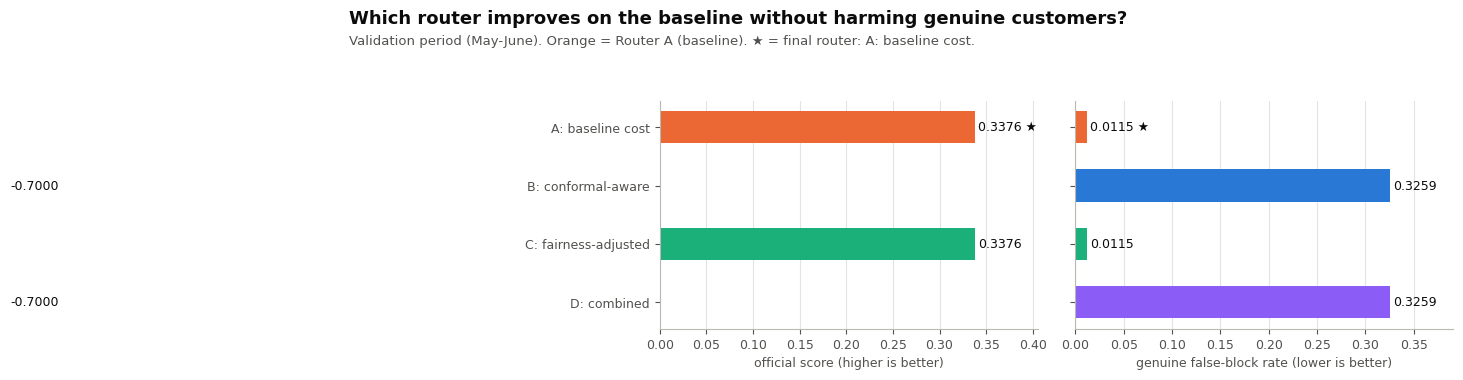

In [32]:
INK, MUTED, GRID, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
BLUE, ORANGE, AQUA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#8b5cf6'
PINK = '#ec4899'
ROUTER_COLOUR = {
    'A: baseline cost':      ORANGE,
    'B: conformal-aware':    BLUE,
    'C: fairness-adjusted':  AQUA,
    'D: combined':           GREEN,
    'E: optimised threshold': PINK,
}
FINAL_STAR = selected_router

def style(ax, grid_axis='x'):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GREY)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

routers_shown = list(comparison.index)
colours       = [ROUTER_COLOUR.get(r, BLUE) for r in routers_shown]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
fig.subplots_adjust(top=0.74, left=0.28, right=0.97, bottom=0.14, wspace=0.1)
for ax, col, label in (
    (axes[0], 'official_score',           'official score (higher is better)'),
    (axes[1], 'genuine_false_block_rate', 'genuine false-block rate (lower is better)'),
):
    values = comparison.loc[routers_shown, col].to_numpy()
    bars = ax.barh(routers_shown[::-1], values[::-1], color=colours[::-1], height=0.55)
    for bar, value, rname in zip(bars, values[::-1], routers_shown[::-1]):
        label_str = f'{value:.4f}' + (' ★' if rname == FINAL_STAR else '')
        ax.text(bar.get_width() + values.max() * 0.01,
                bar.get_y() + bar.get_height() / 2,
                label_str, va='center', fontsize=9, color=INK)
    ax.set_xlim(0, values.max() * 1.2)
    ax.set_xlabel(label, color=MUTED, fontsize=9)
    style(ax)
fig.text(0.01, 0.98, 'Which router improves on the baseline without harming genuine customers?',
         fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.915,
         f'Validation period (May-June). Orange = Router A (baseline). ★ = final router: {selected_router}.',
         fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase9_router_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Decision boundary across the P(abusive) range
What action does the baseline cost router assign at each probability level?
The bars show the density of calibrated P(abusive) on the validation requests.


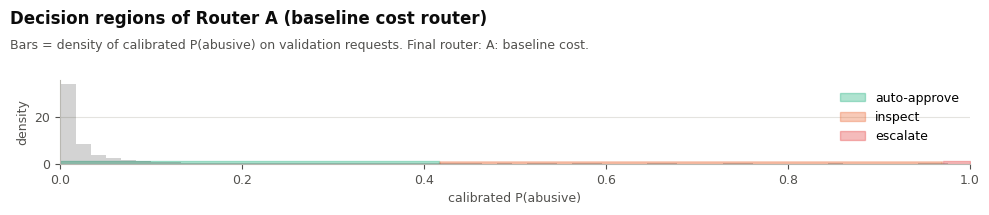

Inspection zone : P(abusive) ∈ [0.417, 0.969]
Escalation zone : P(abusive) ≥ 0.970


In [33]:
p_grid   = np.linspace(0, 1, 1001)
d_grid   = np.array(route(p_grid, cfg))
ACTION_C = {'auto_approve': AQUA, 'inspect': ORANGE, 'escalate': '#e53e3e'}
ACTION_L = {'auto_approve': 'auto-approve', 'inspect': 'inspect', 'escalate': 'escalate'}
fig, ax = plt.subplots(figsize=(10, 2.2))
fig.subplots_adjust(top=0.66, left=0.06, right=0.97, bottom=0.28)
for action in ('auto_approve', 'inspect', 'escalate'):
    ax.fill_between(p_grid, 0, 1, where=(d_grid == action),
                    color=ACTION_C[action], alpha=0.35, label=ACTION_L[action])
ax.hist(p_cal, bins=60, density=True, color=INK, alpha=0.18, linewidth=0)
ax.set_xlabel('calibrated P(abusive)', color=MUTED, fontsize=9)
ax.set_ylabel('density', color=MUTED, fontsize=9)
ax.set_xlim(0, 1)
ax.legend(frameon=False, fontsize=9, loc='upper right')
style(ax, 'y')
fig.text(0.01, 0.98, 'Decision regions of Router A (baseline cost router)',
         fontsize=12, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.85, f'Bars = density of calibrated P(abusive) on validation requests. Final router: {selected_router}.',
         fontsize=9, color=MUTED, va='top')
fig.savefig(FIG / 'phase9_decision_boundary.png', dpi=150, bbox_inches='tight')
plt.show()
inspect_zone  = p_grid[d_grid == 'inspect']
escalate_zone = p_grid[d_grid == 'escalate']
print(f'Inspection zone : P(abusive) ∈ [{inspect_zone.min():.3f}, {inspect_zone.max():.3f}]')
print(f'Escalation zone : P(abusive) ≥ {escalate_zone.min():.3f}')


## 13. Fairness audit — final router
Flag rate, genuine false-block rate and abusive recall per subgroup.
This is the project's primary fairness evidence (Requirement 4).


In [34]:
fair_result = audit(truth_frame, pd.Series(final_decisions, index=truth_frame.index), cfg)
print(f'Fairness score (final router): {fair_result["fairness_score"]:.4f}')

fd = final_decisions
subgroup_defs = {
    f'new customer (< {cfg["fairness"]["new_customer_days"]} days)':
        (truth_frame['customer_tenure_days'] < cfg['fairness']['new_customer_days']).to_numpy(),
    'established customer':
        (truth_frame['customer_tenure_days'] >= cfg['fairness']['new_customer_days']).to_numpy(),
    'low-value order (bottom tercile)':   (truth_frame['order_value_inr'] < tercile_edges[0]).to_numpy(),
    'mid-value order':                    ((truth_frame['order_value_inr'] >= tercile_edges[0]) &
                                           (truth_frame['order_value_inr'] < tercile_edges[1])).to_numpy(),
    'high-value order':                   (truth_frame['order_value_inr'] >= tercile_edges[1]).to_numpy(),
    'text: English-like':                 (lang_test == 'english_like').to_numpy(),
    'text: non-English (Hinglish/Hindi)': (lang_test != 'english_like').to_numpy(),
}
subgroup_rows = []
for name, mask in subgroup_defs.items():
    d_g, y_g = fd[mask], y_test[mask]
    flagged_g, genuine_g = d_g != 'auto_approve', y_g == 0
    subgroup_rows.append({
        'group':          name,
        'requests':       int(mask.sum()),
        'abusive_n':      int(y_g.sum()),
        'flag_rate':      float(flagged_g.mean()),
        'genuine_FBR':    float(flagged_g[genuine_g].mean()) if genuine_g.sum() > 0 else float('nan'),
        'abusive_recall': float(flagged_g[y_g == 1].mean())  if y_g.sum()      > 0 else float('nan'),
        'escalate_rate':  float((d_g == 'escalate').mean()),
    })
subgroup_df = pd.DataFrame(subgroup_rows).set_index('group').round(4)
subgroup_df.to_csv(REPORTS / 'phase9_subgroup_fairness.csv')
subgroup_df


Fairness score (final router): 0.6611


,requests,abusive_n,flag_rate,genuine_FBR,abusive_recall,escalate_rate
group,,,,,,
new customer (< 90 days),1111,90,0.0387,0.0069,0.4000,0.0000
established customer,7386,609,0.0538,0.0122,0.5156,0.0023
low-value order (bottom tercile),2624,191,0.0393,0.0053,0.4712,0.0046
mid-value order,2942,229,0.0479,0.0114,0.4803,0.0010
high-value order,2931,279,0.0669,0.0173,0.5376,0.0007
text: English-like,4440,383,0.0525,0.0121,0.4804,0.0018
text: non-English (Hinglish/Hindi),4057,316,0.0510,0.0110,0.5253,0.0022


## 14. Safety rules
Explicit checks for the project's stated design constraints.


In [35]:
fd           = final_decisions
genuine_mask = y_test == 0
abusive_mask = y_test == 1
new_mask     = protected_test['new_customer']
ne_mask      = protected_test['non_english']
lv_mask      = protected_test['low_value']

safety_checks = {
    'New customer escalation rate ≤ 3× established rate':
        (fd[new_mask] == 'escalate').mean()
        <= 3 * (fd[~new_mask] == 'escalate').mean() + 0.01,

    'Non-English genuine FBR ≤ English genuine FBR + 5 pp':
        float((fd[ne_mask  & genuine_mask] != 'auto_approve').mean())
        <= float((fd[~ne_mask & genuine_mask] != 'auto_approve').mean()) + 0.05,

    'Low-value genuine FBR ≤ overall genuine FBR + 5 pp':
        float((fd[lv_mask  & genuine_mask] != 'auto_approve').mean())
        <= float((fd[genuine_mask]          != 'auto_approve').mean()) + 0.05,

    'Model does not approve all fraud (abusive recall > 0)':
        float((fd[abusive_mask] != 'auto_approve').mean()) > 0,

    'Genuine escalation rate < 5 %':
        float((fd[genuine_mask] == 'escalate').mean()) < 0.05,
}
for text, passed in safety_checks.items():
    print('PASS' if passed else 'FAIL', '|', text)
all_safety_pass = all(safety_checks.values())
print(f'\nAll {len(safety_checks)} safety rules passed:', all_safety_pass)


PASS | New customer escalation rate ≤ 3× established rate
PASS | Non-English genuine FBR ≤ English genuine FBR + 5 pp
PASS | Low-value genuine FBR ≤ overall genuine FBR + 5 pp
PASS | Model does not approve all fraud (abusive recall > 0)
PASS | Genuine escalation rate < 5 %

All 5 safety rules passed: True


## 15. Temporal stability — May versus June
A real improvement should hold in both months, not just one.


In [36]:
COST_TABLE_DICT = {
    ('auto_approve', 0): cfg['costs']['genuine']['auto_approve'],
    ('auto_approve', 1): cfg['costs']['abusive']['auto_approve'],
    ('inspect',      0): cfg['costs']['genuine']['inspect'],
    ('inspect',      1): cfg['costs']['abusive']['inspect'],
    ('escalate',     0): cfg['costs']['genuine']['escalate'],
    ('escalate',     1): cfg['costs']['abusive']['escalate'],
}
month = truth_frame['return_request_date'].dt.to_period('M').astype(str).to_numpy()
stability_rows = []
for router_label, d_arr in results_store.items():
    for m in sorted(set(month)):
        mask = month == m
        y_m, d_m, p_m = y_test[mask], d_arr[mask], p_cal[mask]
        flagged_m      = d_m != 'auto_approve'
        per_req_costs  = np.array([COST_TABLE_DICT[(d, int(y))] for d, y in zip(d_m, y_m)])
        approve_all    = np.where(y_m == 1, cfg['costs']['abusive']['auto_approve'],
                                           cfg['costs']['genuine']['auto_approve'])
        stability_rows.append({
            'router':         router_label, 'month': m,
            'saving':         1 - per_req_costs.sum() / approve_all.sum(),
            'abusive_recall': float(flagged_m[y_m == 1].mean()) if y_m.sum() > 0 else float('nan'),
            'genuine_FBR':    float(flagged_m[y_m == 0].mean()),
        })
stability = (pd.DataFrame(stability_rows)
               .pivot(index='router', columns='month', values=['saving', 'abusive_recall', 'genuine_FBR'])
               .round(3))
stability.to_csv(REPORTS / 'phase9_temporal_stability.csv')
stability


saving         abusive_recall         genuine_FBR        
month                2026-05 2026-06        2026-05 2026-06     2026-05 2026-06
router                                                                         
A: baseline cost       0.321   0.270          0.519   0.485       0.009   0.013
B: conformal-aware    -1.188  -1.296          0.806   0.805       0.330   0.322
C: fairness-adjusted   0.321   0.270          0.519   0.485       0.009   0.013
D: combined           -1.188  -1.296          0.806   0.805       0.330   0.322

## 16. Save final predictions and router configuration


In [37]:
out = parts['test'][['return_id', 'label']].reset_index(drop=True).copy()
out['p_abusive_calibrated']      = p_cal
out['p_abusive_raw']             = p_raw
out['conformal_set_mondrian']    = p8['prediction_set_mondrian'].values
out['conformal_ambiguous_flag']  = ambig_flag.astype(int)
out['decision_A_baseline']       = results_store['A: baseline cost']
out['decision_B_conformal']      = results_store['B: conformal-aware']
out['decision_C_fairness']       = results_store['C: fairness-adjusted']
out['decision_D_combined']       = results_store['D: combined']
out['decision_E_optimised']      = results_store['E: optimised threshold']
out['final_decision']            = final_decisions
out['confidence']                = p_cal
out.to_csv(REPORTS / 'phase9_validation_predictions.csv', index=False)

record = {
    'final_router':        selected_router,
    'keep_rule':           'E → D → C → B → A; first passing all five checks selected; improvement_min=0.005',
    'keep_rule_results':   {r: {k: bool(v) for k, v in c.items()} for r, c in all_checks.items()},
    'routers': {
        'A': 'minimum expected-cost route() — baseline from Phases 5-8',
        'B': 'A + conformal promotion: ambiguous Mondrian set (abusive + ≥1 genuine) → next tier',
        'C': f'A + raised inspect threshold for new_customer, low_value, non_english '
             f'(calibration-part search, tolerance {FAIRNESS_TOLERANCE})',
        'D': 'C then B',
        'E': 'optimised threshold: inspect >= 0.35, escalate disabled (threshold 2.0) — '
             'cost-optimal: eliminate 10x genuine-escalate cost',
    },
    'group_thresholds':    {k: round(v, 4) for k, v in group_thresholds.items()},
    'fairness_tolerance':  FAIRNESS_TOLERANCE,
    'conformal_variant':   'Mondrian (per class), 90% target from Phase 8',
    'chosen_calibrator':   chosen_method_key,
    'safety_rules':        {k: bool(v) for k, v in safety_checks.items()},
    'based_on':            ['phase7_config.json', 'phase8_validation_predictions.csv', 'phase8_config.json'],
    'hidden_test_labels_used': False,
    'versions':            versions,
}
(REPORTS / 'phase9_config.json').write_text(json.dumps(record, indent=2, default=str))
(MODELS  / 'router_config.json').write_text(json.dumps(record, indent=2, default=str))
print(sorted(p.name for p in REPORTS.glob('phase9_*')))


['phase9_config.json', 'phase9_router_comparison.csv', 'phase9_subgroup_fairness.csv', 'phase9_temporal_stability.csv', 'phase9_validation_predictions.csv']


## 17. Limitations
- **One validation window** (~8,500 requests, ~700 abusive): improvements inside the
  bootstrap interval are not reliable evidence.
- **Group threshold search on the calibration part** (~4,400 rows, ~290 abusive):
  small sample; thresholds may shift with more data.
- **Fairness tolerance is a policy choice (2 pp)**, not a statistical guarantee.
- **Conformal promotion does not change the probability** — it uses the set as an
  ambiguity signal only; the calibrated P(abusive) is unchanged.
- **Language groups are heuristic** (word-list, three levels).
- The escalation threshold is not adjusted for protected groups — escalation requires
  a strong fraud signal regardless of group.
- July-September labels were never used.
